# P3. 자주 쓰는 분포와 서로의 관계

**목표**
- 시퀀싱 분석에서 계속 만나는 분포 일곱 개(베르누이, 이항, 포아송, 음이항, 정규, 베타, 감마)를 "어떤 상황에서 나오는가"로 이해합니다.
- 모수(parameter, 분포의 모양을 정하는 숫자)를 바꾸면 모양이 어떻게 바뀌는지 그림으로 봅니다.
- 분포끼리의 관계(어떤 조건에서 하나가 다른 것으로 바뀌는가)와 중심극한정리, 그리고 근사가 틀리는 경우를 시뮬레이션으로 확인합니다.

**이 노트북이 답하는 질문**: read 수, VAF, 깊이, 비율 같은 숫자는 각각 어떤 분포를 따른다고 보고, 왜 그런가요?

**같이 볼 강의·교재**

| 이 노트북 | Harvard Stat 110 강의 [1] | Blitzstein & Hwang 교재 [2] |
|---|---|---|
| 베르누이, 이항 | Lecture 8 Random Variables and Their Distributions | 3장 "Bernoulli and Binomial" 절 |
| 포아송, 이항과의 관계 | Lecture 11 The Poisson distribution | 4장 "Poisson", "Connections between Poisson and Binomial" 절 |
| 음이항 | – | 4장 "Geometric and Negative Binomial" 절 |
| 정규 | Lecture 13 Normal distribution, Lecture 14 Location, Scale, and LOTUS | 5장 "Normal" 절 |
| 베타, 감마 | Lecture 23 Beta distribution, Lecture 24 Gamma distribution and Poisson process | 8장 "Beta", "Gamma", "Beta-Gamma connections" 절 |
| 중심극한정리 | Lecture 29 Law of Large Numbers and Central Limit Theorem | 10장 "Central limit theorem" 절 |

In [1]:
# ---- common start (study_build/stats/_common_p14.py 에서 복사; 고칠 땐 그 파일을 고치고 sync_common.py) ----
# 그림 도구입니다. 펼치지 않아도 됩니다. 팔레트: Okabe-Ito, 색의 뜻은 고정(STYLE §1-3).
import logging, math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, FancyArrowPatch
from scipy import stats

COL = dict(prior="#56B4E9", likelihood="#E69F00", posterior="#0072B2", evidence="#374151",
           A="#0072B2", B="#E69F00", part="#56B4E9", g1="#0072B2", g2="#E69F00",
           sim="#D1D5DB", simedge="#9CA3AF", theory="#222222", null="#9CA3AF",
           highlight="#CC79A7", ok="#009E73", ink="#222222", muted="#6B7280",
           grid="#E5E7EB", none="#E5E7EB", shade="#F3F4F6")
RAMP = ["#C3CAD4", "#98A2B0", "#6B7280", "#3F4652", "#111827"]   # 순서 있는 값(옅음 → 진함)

def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})

def panel(ax, letter, title, **kw):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}" if letter else title, **kw)

def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)

def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨 + 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)

def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)

def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.012):
    """수식을 조각(chip)으로 그린다. parts = [(mathtext, color 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 그림의 같은 색과 짝을 이룬다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); items = []
    for tex, color, label in parts:                        # 조각과 이름표 중 넓은 쪽을 칸 폭으로
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="center",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:
            tl = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = tl.get_window_extent(renderer=r).transformed(inv).width; tl.remove()
        items.append((t, bb, color, label, max(bb.width, lw)))
    total = sum(w for *_, w in items) + gap * (len(items) - 1)
    x = (1 - total) / 2                                    # 가운데 정렬
    for t, bb, color, label, w in items:
        cx = x + w / 2; t.set_x(cx); x += w + gap
        if color:
            ax.add_patch(FancyBboxPatch((cx - bb.width / 2 - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(cx, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)

def concept_map(nodes, edges, figsize=(11, 3.4), title=None, box=(0.13, 0.2), label_dy=0.05):
    """개념 지도. nodes = {키: (x, y, '글자', 색 또는 None)}, edges = [(키1, 키2, '화살표 글자' 또는 '')].
    좌표는 0~1. 색이 있는 상자는 그 색의 옅은 바탕."""
    fig, ax = plt.subplots(figsize=figsize); ax.set_axis_off(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    w, h = box
    for k, (x, y, label, color) in nodes.items():
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.01,rounding_size=0.03",
                                    facecolor=(color or COL["shade"]), alpha=0.22 if color else 1.0,
                                    edgecolor=(color or "#9CA3AF"), lw=1.2))
        ax.text(x, y, label, ha="center", va="center", fontsize=9.5, color=COL["ink"])
    for a, b, label in edges:
        (x1, y1), (x2, y2) = nodes[a][:2], nodes[b][:2]
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12, color="#6B7280",
                                     lw=1.1, shrinkA=38, shrinkB=38, connectionstyle="arc3,rad=0.0"))
        if label:
            vertical = abs(x2 - x1) < 0.03
            ax.text((x1 + x2) / 2 + (0.012 if vertical else 0), (y1 + y2) / 2 + (0 if vertical else label_dy), label,
                    ha="left" if vertical else "center", va="center" if vertical else "bottom", fontsize=8.5,
                    color=COL["muted"], bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
    if title:
        ax.text(0, 1.02, title, fontsize=11.5, fontweight="semibold", transform=ax.transAxes, va="bottom")
    return fig

apply_theme()
# ---- common end ----

def draw_family_map():
    nodes = {"Be": (0.1, 0.74, "Bernoulli\none read: alt?", None),
             "Bi": (0.33, 0.74, "Binomial\nalt reads of n", COL["A"]),
             "Po": (0.56, 0.74, "Poisson\nrare counts", COL["A"]),
             "No": (0.8, 0.74, "Normal\nsums, means", None),
             "BB": (0.14, 0.2, "beta-binomial\nextra-spread VAF", None),
             "Be2": (0.36, 0.2, "Beta\na proportion", None),
             "Ga": (0.6, 0.2, "Gamma\na positive rate", None),
             "NB": (0.84, 0.2, "negative binomial\nextra-spread counts", COL["B"])}
    edges = [("Be", "Bi", "add n"), ("Bi", "Po", "n big, p small"), ("Po", "No", "mean big"),
             ("Bi", "BB", ""), ("Be2", "BB", "p ~ Beta"), ("Po", "NB", ""), ("Ga", "NB", "")]
    fig = concept_map(nodes, edges, figsize=(11.5, 4.2), title="Relationship map: which distribution turns into which",
                      box=(0.15, 0.22), label_dy=0.14)
    ax = fig.axes[0]
    note(ax, 0.19, 0.47, "p itself varies", ha="center", color=COL["ink"])
    note(ax, 0.64, 0.47, "rate itself varies\n(rate ~ Gamma)", ha="right", color="#B7791F")
    return fig

def read_glyph(ax, x, y, alt, w=0.8, h=0.32):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.12",
                                facecolor=COL["B"] if alt else "#D1D5DB", edgecolor="none"))

def draw_binomial_story(n=4, p=0.5):
    from itertools import combinations
    fig = plt.figure(figsize=(11.5, 6.3))
    gs = fig.add_gridspec(2, 2, height_ratios=[0.95, 4], width_ratios=[1, 1.2], hspace=0.12)
    axf = fig.add_subplot(gs[0, :])
    formula_strip(axf, [(r"$P(K=k)$", COL["evidence"], "k alt among n"), (r"$=$", None, None),
                        (r"$\binom{n}{k}$", COL["evidence"], "orders"), (r"$\times$", None, None),
                        (r"$p^{k}$", COL["B"], "alt reads"), (r"$\times$", None, None),
                        (r"$(1-p)^{n-k}$", COL["muted"], "ref reads")], gap=0.02)
    a = fig.add_subplot(gs[1, 0])
    combos = list(combinations(range(n), 2))
    for r, c in enumerate(combos):
        for j in range(n):
            read_glyph(a, j, -r, j in c)
        a.text(n - 0.2, -r, f"{p:.1f}x{p:.1f}x{1 - p:.1f}x{1 - p:.1f} = {p**2 * (1 - p)**2:.4f}", va="center", fontsize=9)
    a.set_xlim(-0.6, n + 3.2); a.set_ylim(-len(combos) + 0.4, 0.9); a.set_axis_off()
    for j in range(n):
        a.text(j, 0.55, f"read {j + 1}", ha="center", fontsize=8.5, color=COL["muted"])
    callout(a, -0.5, -len(combos) + 0.05, f"{len(combos)} orders x 0.0625 = {len(combos) * 0.0625:.3f}", va="center")
    panel(a, "A", f"All orders with 2 alt reads out of {n} (orange = alt)", pad=6)
    a = fig.add_subplot(gs[1, 1])
    k = np.arange(n + 1); pm = stats.binom.pmf(k, n, p)
    a.bar(k, pm, width=0.6, color=[COL["A"] if kk == 2 else RAMP[1] for kk in k])
    for kk, v in zip(k, pm):
        a.text(kk, v + 0.01, f"{v:.4f}", ha="center", fontsize=9.5)
    a.set_xticks(k); a.set_ylim(0, 0.45); ygrid(a)
    a.set_xlabel("k = number of alt reads"); a.set_ylabel("P(K = k)")
    panel(a, "B", f"Binomial(n = {n}, p = {p})")
    return fig, pm[2]

def draw_binomial_shapes(n=30):
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
    k = np.arange(n + 1)
    for a, p, L in zip(ax, [0.05, 0.3, 0.5], "ABC"):
        pm = stats.binom.pmf(k, n, p); mu, sd = n * p, np.sqrt(n * p * (1 - p))
        a.bar(k, pm, width=0.8, color=[COL["B"] if kk >= 3 else RAMP[1] for kk in k])
        note(a, 0.97, 0.95, f"mean np = {mu:.1f}\nSD = {sd:.2f}\nP(K >= 3) = {1 - stats.binom.cdf(2, n, p):.3f}",
             ha="right", va="top", transform=a.transAxes, color=COL["ink"], fontsize=9.5)
        a.set_xlim(-1, n + 1); ygrid(a); a.set_xlabel("alt reads out of 30")
        panel(a, L, f"VAF p = {p}")
    ax[0].set_ylabel("probability")
    callout(ax[0], 0.97, 0.55, "orange: >= 3 alt reads\n(an example threshold)", ha="right", va="top", transform=ax[0].transAxes)
    fig.tight_layout()
    return fig

def draw_poisson_limit(lam=3):
    fig = plt.figure(figsize=(12, 5.6))
    gs = fig.add_gridspec(2, 3, height_ratios=[0.9, 4], hspace=0.15)
    axf = fig.add_subplot(gs[0, :])
    formula_strip(axf, [(r"$P(K=k)$", COL["evidence"], "k events"), (r"$=$", None, None),
                        (r"$\lambda^{k}$", COL["B"], "rate to the k"), (r"$\div$", None, None),
                        (r"$k!$", COL["evidence"], "order does not matter"), (r"$\times$", None, None),
                        (r"$e^{-\lambda}$", COL["muted"], "makes the total 1")])
    k = np.arange(0, 12)
    for i, n in enumerate([10, 50, 1000]):
        a = fig.add_subplot(gs[1, i])
        b = stats.binom.pmf(k, n, lam / n); po = stats.poisson.pmf(k, lam)
        a.bar(k, b, width=0.7, color=RAMP[1], label="binomial")
        a.scatter(k, po, color=COL["ink"], s=22, zorder=3, label="Poisson(3)")
        tv = 0.5 * np.abs(stats.binom.pmf(np.arange(n + 1), n, lam / n) - stats.poisson.pmf(np.arange(n + 1), lam)).sum()
        note(a, 0.97, 0.95, f"n = {n}, p = {lam / n:.3g}\ngap = {tv:.3f}", ha="right", va="top", transform=a.transAxes, color=COL["ink"], fontsize=9.5)
        a.set_ylim(0, 0.32); ygrid(a); a.set_xlabel("k"); a.set_xticks(range(0, 12, 2))
        panel(a, "ABC"[i], f"Binomial(n, 3/n) vs Poisson(3)")
        if i == 0:
            a.set_ylabel("probability")
            note(a, 0.97, 0.7, "bars: binomial\ndots: Poisson", ha="right", va="top", transform=a.transAxes)
    callout(fig.axes[-1], 0.03, 0.98, "n large, p small:\nthe two agree", va="top", transform=fig.axes[-1].transAxes)
    return fig

def draw_overdispersion(mu=200, alpha=0.05, seed=11, n=20000):
    rng = np.random.default_rng(seed)
    shape = 1 / alpha
    rate_by_window = rng.gamma(shape, mu / shape, n)          # 창마다 다른 속도(GC·매핑 등)
    counts_nb = rng.poisson(rate_by_window)
    counts_po = rng.poisson(mu, n)
    fig = plt.figure(figsize=(12, 5.8))
    gs = fig.add_gridspec(2, 2, height_ratios=[0.9, 4], hspace=0.15, wspace=0.22)
    axf = fig.add_subplot(gs[0, :])
    formula_strip(axf, [(r"$\mathrm{Var}(K)$", COL["evidence"], "spread of counts"), (r"$=$", None, None),
                        (r"$\mu$", COL["A"], "Poisson part"), (r"$+$", None, None),
                        (r"$\alpha\,\mu^{2}$", COL["B"], "extra: the rate itself varies")])
    a = fig.add_subplot(gs[1, 0])
    bins = np.arange(0, 600, 6)
    a.hist(counts_po, bins=bins, density=True, color=COL["A"], alpha=0.45, label="Poisson")
    a.hist(counts_nb, bins=bins, density=True, histtype="step", color=COL["B"], lw=1.8, label="gamma-Poisson")
    note(a, 0.98, 0.95, f"same mean {mu}\nPoisson SD {counts_po.std():.0f}\ngamma-Poisson SD {counts_nb.std():.0f}",
         ha="right", va="top", transform=a.transAxes, color=COL["ink"], fontsize=9.5)
    a.text(mu + 18, 0.026, "Poisson", color=COL["A"], fontsize=9.5)
    a.text(mu + 95, 0.004, "gamma-Poisson\n(negative binomial)", color="#B7791F", fontsize=9.5)
    a.set_xlim(0, 520); ygrid(a); a.set_xlabel("reads in a 1 kb window"); a.set_ylabel("density")
    panel(a, "A", "Same mean, very different spread")
    a = fig.add_subplot(gs[1, 1])
    mus = np.geomspace(2, 2000, 25); v_nb, v_po = [], []
    for m in mus:
        r = rng.gamma(shape, m / shape, 3000); v_nb.append(rng.poisson(r).var()); v_po.append(rng.poisson(m, 3000).var())
    a.loglog(mus, v_po, "o", color=COL["A"], ms=4); a.loglog(mus, v_nb, "s", color=COL["B"], ms=4)
    a.loglog(mus, mus, color=COL["A"], lw=1); a.loglog(mus, mus + alpha * mus ** 2, color="#B7791F", lw=1)
    a.text(250, 40, "Var = mean\n(Poisson)", color=COL["A"], fontsize=9.5)
    a.text(2.2, 300, "Var = mean + 0.05 mean²\n(gamma-Poisson)", color="#B7791F", fontsize=9.5)
    callout(a, 0.03, 0.97, "low counts: both look Poisson\nhigh counts: the extra part takes over", va="top", transform=a.transAxes)
    a.set_xlabel("mean count"); a.set_ylabel("variance"); a.grid(True, which="major", color=COL["grid"])
    panel(a, "B", "Variance vs mean")
    return fig, counts_po.var(), counts_nb.var()

def draw_normal():
    fig = plt.figure(figsize=(11, 5.6))
    gs = fig.add_gridspec(2, 1, height_ratios=[0.9, 4], hspace=0.3)
    axf = fig.add_subplot(gs[0])
    formula_strip(axf, [(r"$f(x)$", COL["evidence"], "density"), (r"$=$", None, None),
                        (r"$\frac{1}{\sigma\sqrt{2\pi}}$", COL["muted"], "makes the area 1"), (r"$\times$", None, None),
                        (r"$\exp\!\left(-\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)^{2}\right)$", COL["A"], "falls off with distance in SD units")])
    a = fig.add_subplot(gs[1])
    g = np.linspace(-4, 4, 600); f = stats.norm.pdf(g)
    for k, alp in [(3, 0.12), (2, 0.22), (1, 0.38)]:
        m = np.abs(g) <= k
        a.fill_between(g[m], f[m], color=COL["A"], alpha=alp, lw=0)
    a.plot(g, f, color=COL["ink"], lw=1.6)
    for k in (1, 2, 3):
        pk = stats.norm.cdf(k) - stats.norm.cdf(-k)
        a.annotate("", xy=(k, 0.02 + 0.07 * (3 - k)), xytext=(-k, 0.02 + 0.07 * (3 - k)),
                   arrowprops=dict(arrowstyle="<->", color=COL["ink"], lw=1))
        a.text(0, 0.03 + 0.07 * (3 - k), f"within {k} SD: {pk:.1%}", ha="center", va="bottom", fontsize=9.5,
               bbox=dict(facecolor="white", edgecolor="none", pad=0.8))
    a.set_xticks(range(-4, 5), [f"{t:+d} SD" if t else "mean" for t in range(-4, 5)])
    a.set_ylim(0, 0.44); ygrid(a)
    callout(a, 3.9, 0.4, "z = (x - mean) / SD\nputs any normal on this ruler", ha="right", va="top")
    panel(a, "", "Normal: the 68-95-99.7 picture")
    return fig

def draw_beta():
    g = np.linspace(0.001, 0.999, 500)
    specs = [((1, 1), "flat: no idea"), ((2, 2), "mild: near 0.5"), ((0.5, 0.5), "U: near 0 or 1"),
             ((8, 2), "near 0.8"), ((2, 8), "near 0.2"), ((30, 70), "sure: near 0.3")]
    fig, ax = plt.subplots(2, 3, figsize=(11.5, 5.4), sharex=True)
    for a, ((al, be), lab), L in zip(ax.ravel(), specs, "ABCDEF"):
        f = stats.beta.pdf(g, al, be)
        a.fill_between(g, f, color=COL["prior"], alpha=0.35, lw=0); a.plot(g, f, color=COL["ink"], lw=1.3)
        a.set_ylim(0, min(f.max() * 1.25, 10)); ygrid(a)
        xy = (0.5, 0.55) if (al, be) == (0.5, 0.5) else (0.97, 0.95)
        note(a, *xy, f"mean {al / (al + be):.2f}", ha="center" if xy[0] == 0.5 else "right", va="top", transform=a.transAxes, color=COL["ink"], fontsize=9.5)
        panel(a, L, f"Beta({al}, {be}): {lab}")
    for a in ax[1]:
        a.set_xlabel("a proportion (VAF, purity, ...)")
    callout(ax[1, 2], 0.97, 0.55, "a distribution over\nvalues between 0 and 1", ha="right", va="top", transform=ax[1, 2].transAxes)
    fig.tight_layout()
    return fig

def draw_gamma():
    g = np.linspace(0, 30, 600)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    for k, c in zip([1, 2, 5, 10], RAMP[1:]):
        f = stats.gamma.pdf(g, k, scale=1.5)
        ax.plot(g, f, color=c, lw=1.8)
        i = np.argmax(f); ax.text(g[i] + 0.4, f[i] + 0.01, f"shape {k}", color=c, fontsize=9.5)
    ax.set_ylim(0, 0.72); ygrid(ax); ax.set_xlabel("x (always > 0)"); ax.set_ylabel("density")
    callout(ax, 29.5, 0.6, "Gamma(shape s, scale 1.5): waiting time for s events,\nor a spread of positive rates", ha="right", va="top")
    ax.set_title("Gamma: positive values, from skewed to bell-like")
    fig.tight_layout()
    return fig

def draw_clt(seed=12):
    rng = np.random.default_rng(seed)
    fig, ax = plt.subplots(2, 4, figsize=(12.5, 6.0))
    for a, n, L in zip(ax[0], [1, 2, 5, 30], "ABCD"):
        m = rng.exponential(1, (40000, n)).mean(1)
        a.hist(m, bins=60, density=True, color=COL["sim"], edgecolor="white", lw=0.3)
        g = np.linspace(max(0, m.min()), m.max(), 300)
        a.plot(g, stats.norm.pdf(g, 1, 1 / np.sqrt(n)), color=COL["ink"], lw=1.3, ls=(0, (4, 2)))
        panel(a, L, f"mean of {n} skewed draws"); ygrid(a)
        a.set_xlim(0, 4 if n < 5 else 2.5)
    note(ax[0, 0], 0.97, 0.95, "grey: simulation\ndashed: normal curve", ha="right", va="top", transform=ax[0, 0].transAxes)
    callout(ax[0, 3], 0.97, 0.95, "close to normal", ha="right", va="top", transform=ax[0, 3].transAxes)
    a = ax[1, 0]
    x = rng.standard_cauchy(100000); run = np.cumsum(x) / np.arange(1, len(x) + 1)
    y = rng.normal(0, 1, 100000); runy = np.cumsum(y) / np.arange(1, len(y) + 1)
    a.plot(run, color=COL["B"], lw=1); a.plot(runy, color=COL["A"], lw=1)
    a.set_xscale("log"); a.set_ylim(-6, 6); ygrid(a); a.set_xlabel("n (log)")
    a.text(1.3e5, np.clip(run[-1], -5.5, 5.5), "Cauchy", color="#B7791F", fontsize=9.5, va="center")
    a.text(1.3e5, runy[-1] + 0.6, "normal", color=COL["A"], fontsize=9.5, va="center")
    a.set_xlim(None, 2e6)
    panel(a, "E", "Running mean")
    a = ax[1, 1]
    for n, c in [(10, RAMP[1]), (1000, COL["ink"])]:
        mc = rng.standard_cauchy((20000, n)).mean(1)
        keep = np.abs(mc) < 15
        a.hist(mc[keep], bins=np.linspace(-15, 15, 61), density=True, histtype="step", color=c, lw=2.6 if n == 10 else 1.1)
    a.text(3.2, 0.27, "thick grey: n = 10\nthin black: n = 1000\nsame width\n(beyond ±15 not shown)", fontsize=9, va="top")
    callout(a, 0.03, 0.97, "no finite variance: no CLT", va="top", transform=a.transAxes)
    a.set_xlim(-15, 15); ygrid(a); a.set_xlabel("mean of n Cauchy draws")
    panel(a, "F", "Heavy tails: never narrows")
    for a, (n, p, L) in zip(ax[1, 2:], [(50, 0.02, "G"), (50, 0.4, "H")]):
        k = np.arange(0, n + 1); b = stats.binom.pmf(k, n, p)
        mu, sd = n * p, np.sqrt(n * p * (1 - p))
        a.bar(k, b, width=0.8, color=RAMP[1])
        g = np.linspace(-3, n, 500); a.plot(g, stats.norm.pdf(g, mu, sd), color=COL["ink"], lw=1.2, ls=(0, (4, 2)))
        lo, hi = (-2, 8) if p < 0.1 else (8, 32); a.set_xlim(lo, hi); ygrid(a)
        panel(a, L, f"Binomial({n}, {p}) vs normal"); a.set_xlabel("k")
        if p < 0.1:
            callout(a, 0.97, 0.95, f"np = {n * p:.0f}: normal puts\n{stats.norm.cdf(-0.5, mu, sd):.0%} below 0", ha="right", va="top", transform=a.transAxes)
        else:
            note(a, 0.97, 0.95, f"np = {n * p:.0f}: fine", ha="right", va="top", transform=a.transAxes, color=COL["ink"], fontsize=9.5)
    fig.tight_layout()
    return fig

## 관계 지도

이 노트북의 지도입니다. 화살표 옆 글자가 "어떤 조건에서 왼쪽이 오른쪽으로 바뀌는가"입니다. 아래 절을 하나씩 지나면서 각 화살표를 확인합니다.

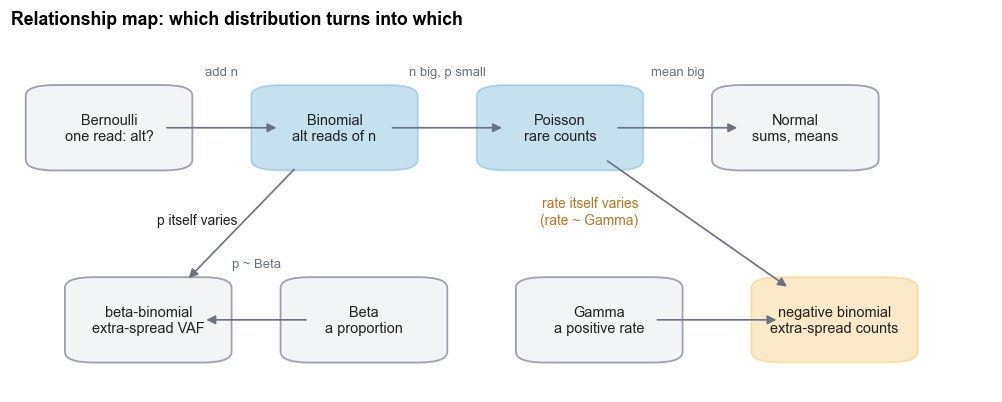

In [2]:
fig = draw_family_map(); plt.show()

**그림에서 볼 것**
- 윗줄: read 하나(베르누이)를 n 개 모으면 이항, n 이 크고 확률이 작으면 포아송, 평균이 크면 정규에 가까워집니다.
- 아랫줄: 포아송의 속도(평균) 자체가 감마 분포로 흔들리면 음이항이 됩니다. 이항의 확률 p 자체가 베타로 흔들리면 베타-이항이 됩니다(P7, P9).

## 먼저 알아 둘 것: 모수와 기호

| 기호 | 소리 내어 읽기 | 뜻 |
|---|---|---|
| 모수 (parameter) | "분포의 손잡이" | 분포의 모양을 정하는 숫자. 이항의 n, p, 정규의 μ, σ 처럼 |
| $K \sim \mathrm{Bin}(n, p)$ | "K 는 n, p 인 이항 분포를 따른다" | ~ 는 "이 분포를 따른다" |
| $\binom{n}{k}$ | "n 개 중 k 개를 고르는 경우의 수" | $n! / (k!(n-k)!)$ |
| $k!$ | "k 팩토리얼" | $k \times (k-1) \times \dots \times 1$ |
| $e^{x}$, $\exp(x)$ | "e 의 x 제곱" | e ≈ 2.718 |
| $\mu, \sigma$ | "뮤", "시그마" | 평균, 표준편차 |

## 1. 베르누이와 이항: alt read 세기

**한 줄 정의**: 베르누이는 "한 번 해서 성공(1) 또는 실패(0)", 이항 $\mathrm{Bin}(n, p)$ 은 "성공 확률 p 인 독립 시행 n 번 중 성공 횟수"입니다 [2].

**왜 필요한가**: 한 자리를 덮는 read 하나하나가 "alt 냐 아니냐"의 베르누이이고, 그 자리의 alt read 수가 이항입니다. VAF 를 다루는 거의 모든 계산의 출발점입니다.

**숫자로 따라가기** (read 4 개, 각 read 가 alt 일 확률 0.5, alt 가 정확히 2 개일 확률)
- 어느 read 가 alt 인지 순서가 6 가지입니다(4 개 중 2 개 고르기, $\binom{4}{2} = 6$).
- 순서 하나의 확률은 $0.5 \times 0.5 \times 0.5 \times 0.5 = 0.0625$ 입니다.
- 그래서 $P(K = 2) = 6 \times 0.0625 = 0.375$ 입니다.

**수식 풀어 읽기**

$$P(K = k) = \binom{n}{k}\, p^{k} (1 - p)^{n-k}$$

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\binom{n}{k}$ | "n 개 중 k 개 고르기" | alt 가 어느 자리에 오는지 순서의 수 | A 의 줄 수 6 |
| $p^{k}$ | "p 의 k 제곱" | alt read k 개가 모두 alt 일 확률 | A 의 주황 read |
| $(1-p)^{n-k}$ | "1 빼기 p 의 n 빼기 k 제곱" | 나머지가 모두 ref 일 확률 | A 의 회색 read |

식은 SciPy `binom` 문서의 PMF 와 같습니다 [3].

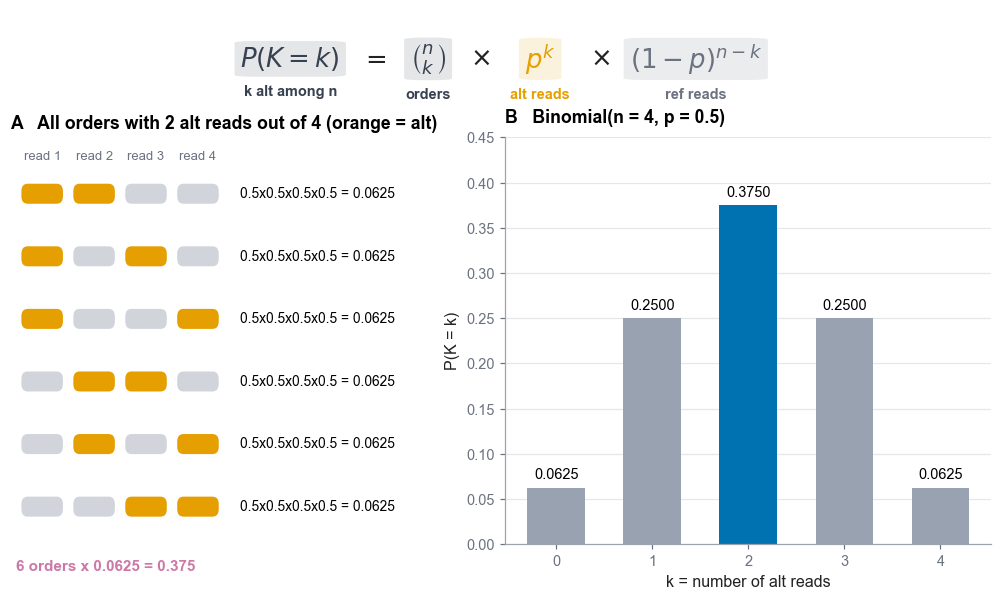

In [3]:
fig, p2 = draw_binomial_story(); plt.show()
sim = np.random.default_rng(20).binomial(4, 0.5, 200_000)
assert abs(p2 - 0.375) < 1e-12 and abs((sim == 2).mean() - 0.375) < 0.005

**그림에서 볼 것**
- A: 한 줄이 순서 하나입니다. 6 줄 모두 확률이 0.0625 로 같아서, 합치면 0.375 입니다.
- B: 이항 분포의 막대 다섯 개 중 k = 2(파랑)가 0.375 로 A 의 합과 같습니다.

### VAF 에 따라 이항 분포의 모양이 바뀝니다

**숫자로 따라가기**: 깊이 30 에서 VAF 0.05, 0.3, 0.5 인 변이의 alt read 수. 평균은 $np$, SD 는 $\sqrt{np(1-p)}$ 입니다 [2].
VAF 0.05 면 평균 1.5 개라, alt read 를 3 개 이상 요구하면 대부분 놓칩니다.

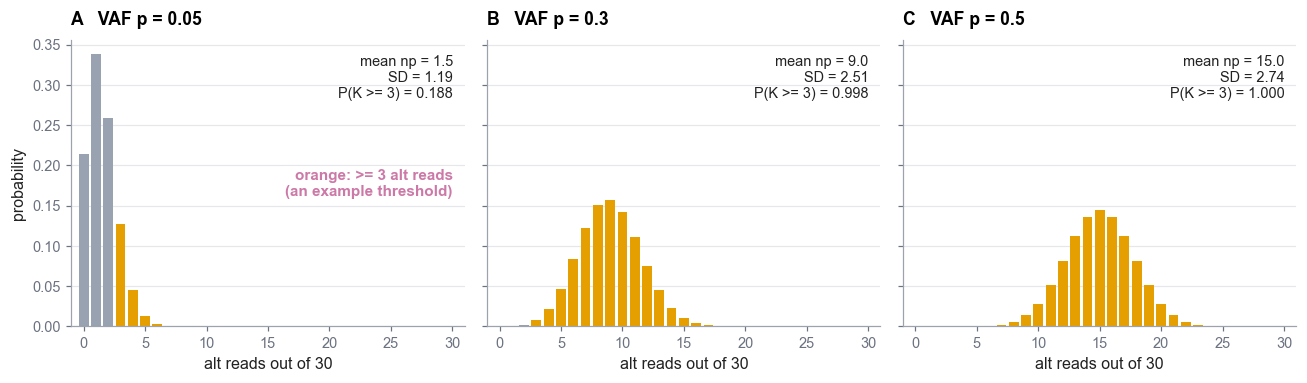

In [4]:
fig = draw_binomial_shapes(); plt.show()
assert abs((1 - stats.binom.cdf(2, 30, 0.05)) - 0.188) < 1e-3
for p in (0.05, 0.3, 0.5):      # 평균 np, SD √(np(1-p)) 를 SciPy 와 맞춰 보기
    assert abs(stats.binom.mean(30, p) - 30 * p) < 1e-12 and abs(stats.binom.std(30, p) - np.sqrt(30 * p * (1 - p))) < 1e-12

**그림에서 볼 것**
- A→C: VAF 가 커지면 분포가 오른쪽으로 가고 넓어집니다. SD 는 p = 0.5 에서 가장 큽니다($p(1-p)$ 가 최대).
- 주황 막대는 "alt read 3 개 이상" 입니다. VAF 0.05 에서는 이 확률이 0.188 뿐입니다.

> **시퀀싱 데이터에서는**: purity 를 ρ(로)라고 쓰면(위의 p 와 헷갈리지 않게), 이배체 종양에서 클론 이형접합 변이의 alt read 수는 대략 $\mathrm{Bin}(\text{깊이}, \rho/2)$ 입니다(P1 8 절, PURPLE B1).
> 실제 변이 호출기마다 alt read 최소 개수 같은 기준이 다르므로, 위의 "3 개"는 설명용 예입니다.

## 2. 포아송: 드문 일을 센다

**한 줄 정의**: 포아송 $\mathrm{Pois}(\lambda)$ 는 "평균 λ 번 일어나는 드문 일이 실제로 몇 번 일어났나"의 분포이고, 평균과 분산이 모두 λ 입니다 [2].

**왜 필요한가**: 유전체 30 억 자리 중 한 1 kb 창에서 시작하는 read 수처럼, "기회는 아주 많고 하나하나의 확률은 아주 작은" 수를 셀 때 이항의 n 과 p 를 따로 알 필요 없이 평균 하나로 다룹니다.

**숫자로 따라가기**: 이항 $\mathrm{Bin}(n, 3/n)$ 에서 n 을 10 → 50 → 1000 으로 늘리면(평균은 늘 3), 분포가 $\mathrm{Pois}(3)$ 에 붙습니다.
교재 4 장에 "Connections between Poisson and Binomial" 절이 있습니다(목차 기준) [2]. 이 관계는 아래 그림에서 직접 확인합니다.

**수식 풀어 읽기**

$$P(K = k) = \frac{\lambda^{k}}{k!}\, e^{-\lambda}$$

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\lambda$ | "람다" | 평균 횟수 | 막대가 몰린 곳 3 |
| $\lambda^{k} / k!$ | "람다의 k 제곱 나누기 k 팩토리얼" | k 번 일어나는 몫(순서는 상관없어서 k! 로 나눔) | 막대 높이의 모양 |
| $e^{-\lambda}$ | "e 의 마이너스 람다 제곱" | 전체 합이 1 이 되게 하는 수 (k = 0 일 확률이기도 함) | k = 0 막대 높이 0.050 |

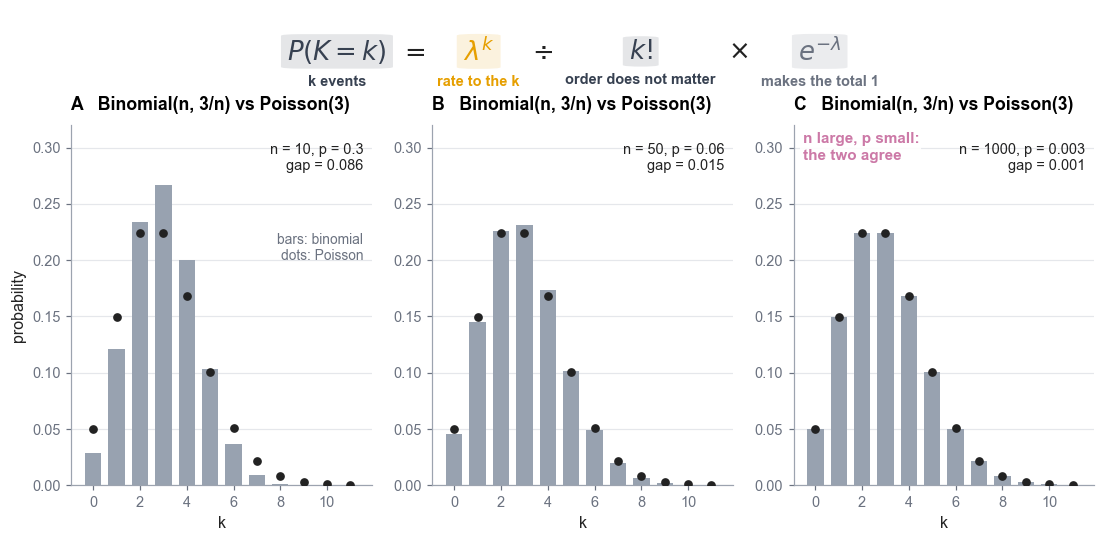

In [5]:
fig = draw_poisson_limit(); plt.show()
assert abs(stats.poisson.pmf(0, 3) - np.exp(-3)) < 1e-12
x = np.random.default_rng(21).poisson(3, 300_000)
assert abs(x.mean() - 3) < 0.02 and abs(x.var() - 3) < 0.03

**그림에서 볼 것**
- 회색 막대(이항)와 검은 점(포아송)이 n = 10 에서는 어긋나고, n = 1000 에서는 겹칩니다. "gap"(두 분포가 다른 정도, 절대 차이 합의 절반)이 0.086 → 0.015 → 0.001 으로 줄어듭니다.

> **시퀀싱 데이터에서는**: 깊이 30x, read 150 bp 이면 1 kb 창에 시작하는 read 수는 평균 $30 \times 1000 / 150 = 200$ 인 포아송에 가깝고, SD 는 $\sqrt{200} = 14$ (7%) 입니다.
> 이것이 PURPLE B0 노트북 6 절의 "1 kb 창의 세기 잡음"입니다(짝 read 를 고려하면 더 커진다는 점도 거기서 봤습니다).

## 3. 음이항: 포아송보다 더 퍼진 수

**한 줄 정의**: 포아송의 평균 자체가 창마다(또는 시료마다) 감마 분포를 따라 흔들리면, 그렇게 섞인 수는 음이항 분포를 따르고 분산이 평균보다 커집니다(과분산, overdispersion). DESeq2 논문이 음이항을 "감마-포아송 분포라고도 한다"고 적은 것이 이 관계입니다 [4]. 아래 그림의 시뮬레이션도 감마에서 속도를 뽑은 뒤 포아송으로 센 것입니다.

**왜 필요한가**: 실제 시퀀싱 수는 포아송보다 더 퍼져 있는 경우가 많습니다. 예를 들어 RNA-seq 에서는 같은 조건의 반복 시료 사이에도 유전자 발현이 흔들려, DESeq2 는 이 흔들림을 과분산 α 로 모델합니다 [4]. 포아송으로 다루면 퍼짐을 과소평가해 차이를 너무 쉽게 "유의"하다고 하게 됩니다(이 결론은 이 노트북의 설명이며, 아래 그림이 퍼짐 차이를 보여 줍니다).

**숫자로 따라가기** (평균 200, 과분산 α = 0.05)
- 포아송 분산: 200 (SD 14)
- 음이항 분산: $200 + 0.05 \times 200^2 = 2200$ (SD 47)
- 평균은 같은데 SD 가 3 배 넘게 큽니다.
- SciPy 의 `nbinom(n, p)` 로 쓰면 $n = \mu^2/(\sigma^2 - \mu) = 1/\alpha$ (여기서는 20), $p = \mu/\sigma^2 = n/(n + \mu)$ 입니다 [3].

**수식 풀어 읽기**

$$\mathrm{Var}(K) = \mu + \alpha\,\mu^{2}$$

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\mu$ | "뮤" | 평균. 포아송이라면 분산도 이것뿐 | B 의 파란 선 |
| $\alpha$ | "알파", 과분산 계수 | 속도가 창마다 얼마나 흔들리나 | – |
| $\alpha\mu^{2}$ | "알파 뮤 제곱" | 속도가 흔들려서 생긴 추가 분산. 평균이 커지면 이쪽이 지배 | B 의 주황 선이 파란 선에서 멀어지는 부분 |

DESeq2 논문은 read 수를 "음이항 분포(감마-포아송 분포라고도 함)"로 모델하고, 분산을 바로 이 식 $v = \mu + \alpha\mu^2$ 로 적습니다 [4].
SciPy `nbinom` 문서도 같은 꼴 $\sigma^2 = \mu + \alpha\mu^2$ 을 예로 들고 $n = \mu^2/(\sigma^2 - \mu)$, $p = \mu/\sigma^2$ 로 바꾸는 법을 적습니다 [3].

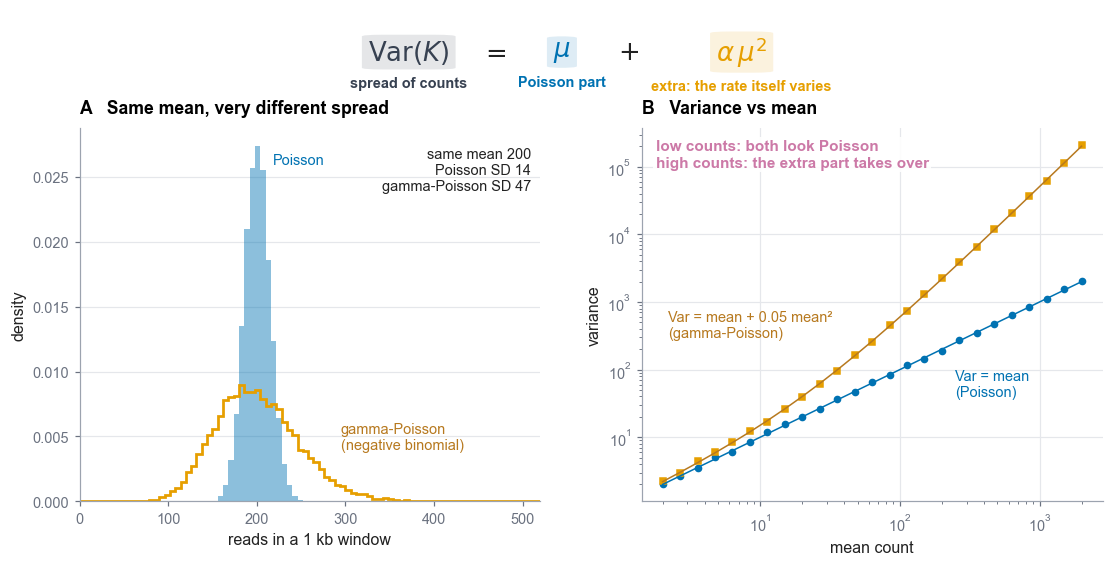

포아송 분산(시뮬레이션): 202   감마-포아송 분산(시뮬레이션): 2199   식: 2200.0


In [6]:
fig, v_po, v_nb = draw_overdispersion(); plt.show()
mu, alpha = 200, 0.05
n_, p_ = 1 / alpha, (1 / alpha) / (1 / alpha + mu)
assert abs(stats.nbinom.var(n_, p_) - (mu + alpha * mu ** 2)) < 1e-6
assert abs(v_po - mu) < 10 and abs(v_nb - (mu + alpha * mu ** 2)) < 150
print("포아송 분산(시뮬레이션):", round(v_po), "  감마-포아송 분산(시뮬레이션):", round(v_nb), "  식:", mu + alpha * mu ** 2)

**그림에서 볼 것**
- A: 파란 히스토그램(포아송)과 주황 선(감마-포아송)은 평균이 200 으로 같지만 주황이 훨씬 넓습니다.
- B: 로그 눈금에서 평균이 작을 때는 두 분산이 비슷하고(둘 다 파란 선 근처), 평균이 커지면 주황 점이 $\mu + \alpha\mu^2$ 곡선을 따라 위로 갈라집니다.

> **시퀀싱 데이터에서는**
> - RNA-seq: DESeq2 는 유전자별 read 수를 음이항으로 두고, 과분산 α 를 "같은 조건 반복 시료 사이의 흔들림"(within-group variability, i.e., the variability between replicates)으로 설명합니다 [4].
> - WGS 깊이: 창마다 기대 깊이를 바꾸는 요인 중 GC 함량처럼 **방향이 정해진** 치우침은 무작위 흔들림이라기보다 예측할 수 있는 편향이라, COBALT 는 GC 구간마다 깊이의 중앙값으로 나눠 따로 보정합니다 [7](PURPLE B1 노트북). 이 그림의 감마 속도처럼 "무작위로 흔들리는 기대값"과는 다른 이야기입니다.

## 4. 정규분포: 많이 더한 것의 모양

**한 줄 정의**: 정규분포 $N(\mu, \sigma^2)$ 는 평균 μ 를 중심으로 좌우 대칭인 종 모양이고, 평균에서 SD 몇 배 떨어졌는지만으로 확률이 정해집니다 [2].

**왜 필요한가**: 많은 독립적인 작은 효과를 더한 값(창 여러 개의 평균 깊이 비, 표본 평균)은 정규에 가까워집니다(6 절). 그래서 검정과 신뢰구간 대부분이 정규를 씁니다.

**숫자로 따라가기**: 평균에서 ±1 SD 안에 68.3%, ±2 SD 안에 95.4%, ±3 SD 안에 99.7% 가 들어갑니다. 어떤 정규 값 x 든 $z = (x - \mu)/\sigma$ 로 바꾸면 같은 자로 잴 수 있습니다.

**수식 풀어 읽기**

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\exp\!\left(-\frac{1}{2}\left(\frac{x - \mu}{\sigma}\right)^{2}\right)$$

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $(x - \mu)/\sigma$ | "x 빼기 뮤 나누기 시그마", z | 평균에서 SD 몇 배 떨어졌나 | 가로축 눈금 "+1 SD" 등 |
| $\exp(-\frac{1}{2}z^2)$ | "e 의 마이너스 이분의 일 z 제곱" | 떨어질수록 빠르게 작아짐. z = 0 에서 가장 큼 | 곡선의 모양 |
| $\frac{1}{\sigma\sqrt{2\pi}}$ | "시그마 루트 이 파이 분의 일" | 곡선 아래 넓이를 1 로 맞추는 수 | 꼭대기 높이 0.399 (σ = 1) |

SciPy `norm` 문서의 표준형 PDF 가 이 식에서 μ = 0, σ = 1 인 경우입니다 [3].

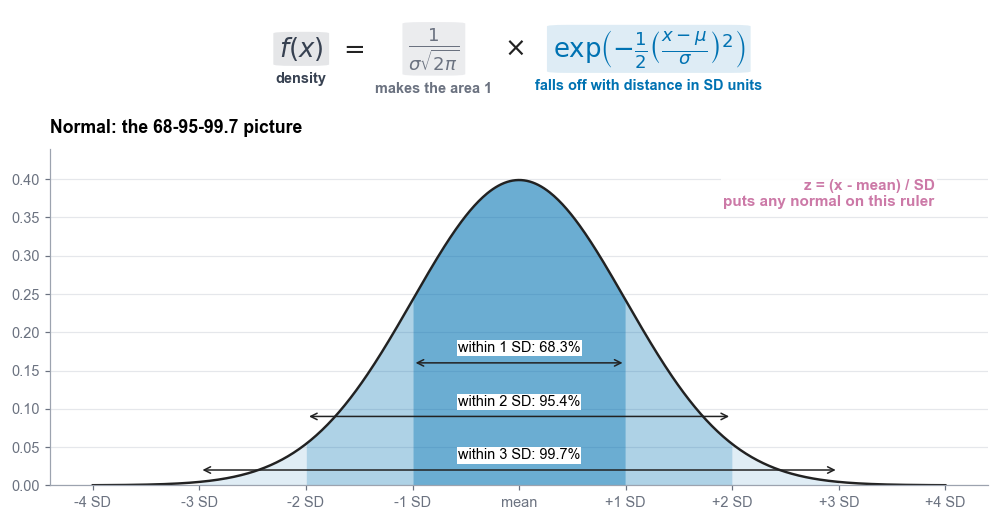

In [7]:
fig = draw_normal(); plt.show()
zz = np.random.default_rng(22).normal(0, 1, 400_000)
for k, target in [(1, 0.6827), (2, 0.9545), (3, 0.9973)]:
    assert abs((np.abs(zz) < k).mean() - target) < 0.003

**그림에서 볼 것**
- 가장 진한 파랑(±1 SD)에 68.3%, 그다음 띠까지(±2 SD) 95.4%, 가장 옅은 띠까지(±3 SD) 99.7% 가 들어갑니다.
- 가로축이 원래 단위가 아니라 "SD 몇 배"로 적혀 있습니다. z 점수로 바꾸면 모든 정규가 이 그림 하나로 읽힙니다.

## 5. 베타와 감마: 비율의 분포, 양수의 분포

### 베타: 0 과 1 사이 값(비율)에 대한 분포

**한 줄 정의**: 베타 $\mathrm{Beta}(a, b)$ 는 0 과 1 사이에서만 값을 갖는 분포라서, "VAF 나 purity 가 대략 얼마쯤일까"라는 **불확실성**을 표현하는 데 씁니다 [2].

**왜 필요한가**: 이항의 p 를 하나의 숫자로 고정하지 않고 "이쯤일 가능성이 크다"는 모양으로 나타낼 수 있습니다. P7 에서 사전 분포로 쓰고, 데이터를 보면 다시 베타가 되는 편리한 성질을 봅니다.

**숫자로 따라가기**: 평균은 $a/(a + b)$ 입니다(3 절의 과분산 α 와 헷갈리지 않게, SciPy `beta` 처럼 a, b 로 씁니다 [3]). Beta(30, 70) 은 평균 0.3 이고 좁습니다("0.3 근처라고 꽤 확신"). Beta(1, 1) 은 0~1 이 모두 같은 높이("전혀 모름")입니다.

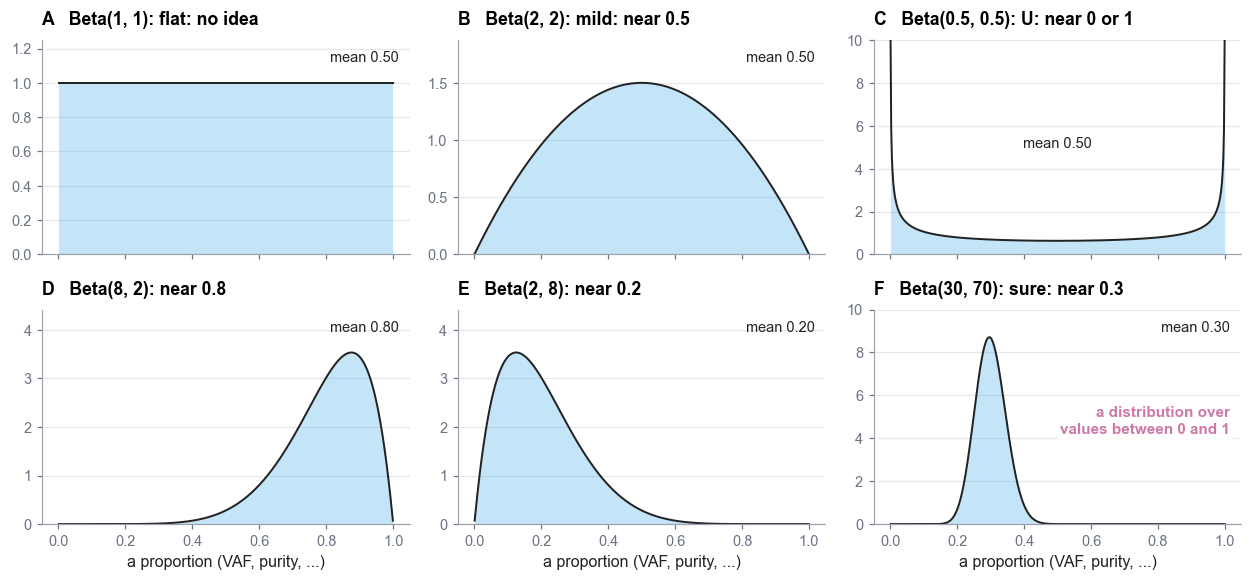

In [8]:
fig = draw_beta(); plt.show()
assert abs(stats.beta.mean(30, 70) - 0.3) < 1e-12 and abs(stats.beta.pdf(0.42, 1, 1) - 1) < 1e-12

**그림에서 볼 것**
- A: 평평함(모든 값이 같은 가능성). B: 0.5 근처가 조금 더 그럴듯. C: 0 이나 1 근처가 그럴듯(U 자).
- D, E: 0.8 근처, 0.2 근처로 치우침. F: a + b 가 크면(100) 좁아집니다. 확신이 클수록 좁은 베타입니다.

### 감마: 0 보다 큰 값의 분포

**한 줄 정의**: 감마 $\mathrm{Gamma}(s, \theta)$ (모양 s, 척도 θ)는 0 보다 큰 값에 대한 분포로, "평균 간격 θ 로 일어나는 일이 s 번 일어날 때까지 기다리는 시간"의 분포이자, "속도(rate) 같은 양수의 흔들림"을 나타내는 데 씁니다 [2].
척도 θ 대신 속도(rate) $1/\theta$ 로 쓰는 책도 많습니다. SciPy `gamma` 문서는 rate 로 쓴 꼴이 `scale = 1 / beta` 와 같다고 적습니다 [3]. 기호가 책마다 다르니 "θ 가 평균을 키우는지(척도), 줄이는지(속도)"를 먼저 확인하세요.

**숫자로 따라가기**: 평균은 $s\theta$ 입니다. 모양 s = 1 이면 오른쪽으로 긴 꼬리(지수 분포), s 가 커질수록 종 모양에 가까워집니다. 3 절의 "창마다 다른 속도"가 바로 감마에서 뽑은 값이었습니다.

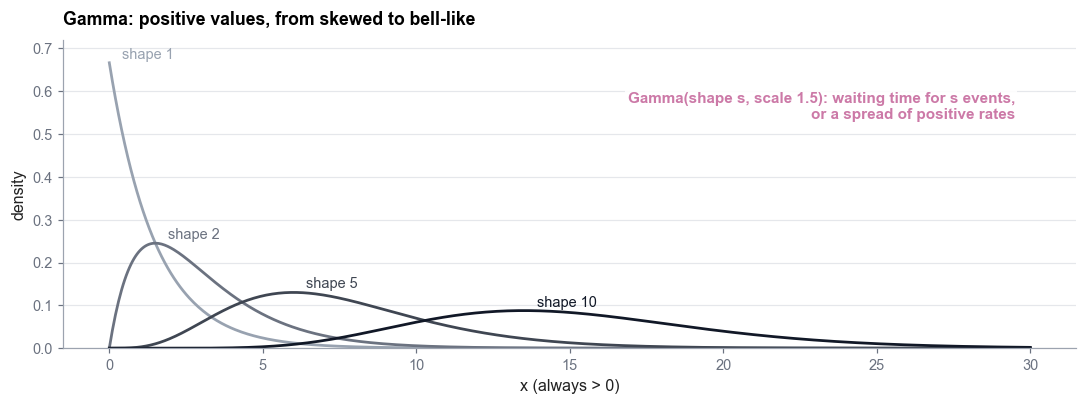

In [9]:
fig = draw_gamma(); plt.show()
assert abs(stats.gamma.mean(5, scale=1.5) - 7.5) < 1e-12

**그림에서 볼 것**
- 회색이 진해질수록 shape 가 큽니다(1, 2, 5, 10). shape 1 은 0 에서 가장 높고 꼬리가 길며, shape 10 은 15 근처를 중심으로 한 종 모양입니다.

> **시퀀싱 데이터에서는**: 베타는 VAF·purity·CCF 같은 비율의 불확실성(P7–P9), 감마는 창별 기대 깊이나 과분산 모델의 속도(3 절)에 쓰입니다.

## 6. 중심극한정리와, 근사가 틀리는 경우

**한 줄 정의**: 같은 분포를 따르고 **평균과 분산이 있는(유한한)** 독립인 값을 많이 모아 평균을 내면, 원래 분포가 치우쳐 있어도 평균의 분포는 정규에 가까워지고, 그 SD 는 $\sigma/\sqrt{n}$ 으로 줄어듭니다(중심극한정리) [8].

**왜 필요한가**: 원래 분포를 몰라도 "평균"에 대해서는 정규를 써서 검정·구간을 계산할 수 있는 근거입니다. 다만 늘 되는 것은 아니어서, 안 되는 경우를 함께 알아야 합니다.

**숫자로 따라가기**: 평균 1, SD 1 인 치우친 분포(지수 분포)에서 n = 30 개씩 뽑아 평균을 내면, 평균들의 SD 는 $1/\sqrt{30} = 0.18$ 입니다.

아래 그림의 아랫줄은 근사가 틀리는 두 경우입니다.
- **꼬리가 너무 무거울 때**: 코시 분포는 평균도 분산도 정의되지 않아(SciPy 도 `cauchy.mean()`, `cauchy.var()` 를 nan 으로 돌려줍니다) 정리의 조건을 만족하지 않습니다. 몇 개를 모아 평균을 내도 넓이가 그대로입니다.
- **수가 작고 0 근처일 때**: $\mathrm{Bin}(50, 0.02)$ (평균 1)를 정규로 근사하면, 있을 수 없는 음수 쪽에 확률을 줍니다.

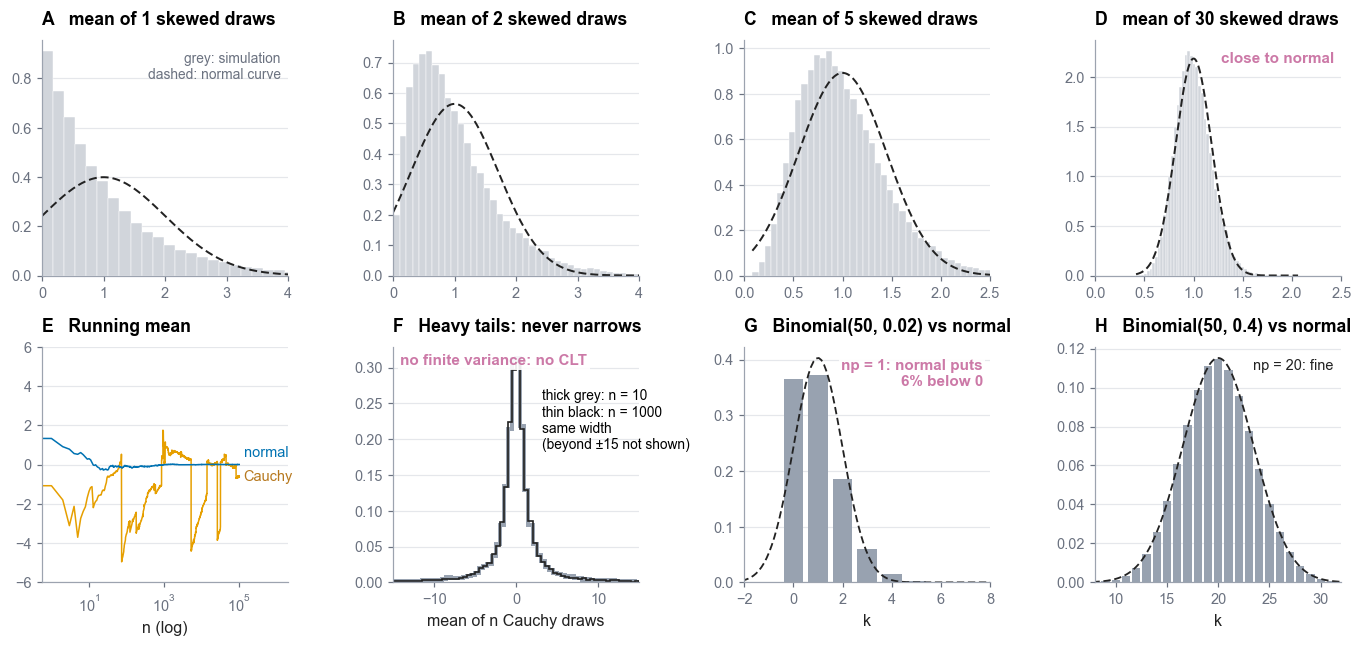

In [10]:
fig = draw_clt(); plt.show()
m30 = np.random.default_rng(23).exponential(1, (100_000, 30)).mean(1)
assert abs(m30.std() - 1 / np.sqrt(30)) < 0.005 and np.isnan(stats.cauchy.mean()) and np.isnan(stats.cauchy.var())

**그림에서 볼 것**
- A→D: 치우친 분포의 평균을 1, 2, 5, 30 개로 낼수록 회색 히스토그램이 점선 정규 곡선에 붙습니다.
- E: 정규 값의 누적 평균(파랑)은 0 에 수렴하지만, 코시의 누적 평균(주황)은 가끔 큰 값에 튀어 끝까지 자리를 잡지 못합니다.
- F: 코시 10 개 평균과 1000 개 평균의 분포가 같은 넓이입니다. 이것은 이 노트북의 시뮬레이션 결과입니다.
- G: 평균 1 인 이항을 정규로 근사하면 점선이 0 왼쪽까지 넘어갑니다. H: 평균 20 이면 잘 맞습니다.

> **시퀀싱 데이터에서는**: alt read 가 0~3 개인 저빈도 변이처럼 수가 작으면 정규 근사(z 검정 등) 대신 이항·포아송을 그대로 쓰는 편이 안전합니다.
> 반대로 수백 개 창의 깊이 비를 평균한 구간 값은 정규에 가깝게 다룰 수 있습니다.

**직접 바꿔 보기**: 아래 셀의 `p` 를 0.02 → 0.1 → 0.3 으로 바꿔, 깊이 50 에서 정규 근사가 언제부터 괜찮아지는지(음수 쪽 확률이 거의 0 이 되는지) 보세요.

In [11]:
n_, p_ = 50, 0.02
print("정규 근사가 0 미만에 주는 확률:", round(stats.norm.cdf(-0.5, n_ * p_, np.sqrt(n_ * p_ * (1 - p_))), 3))

정규 근사가 0 미만에 주는 확률: 0.065


## 연습 문제

1. 깊이 40, VAF 0.25 인 변이에서 alt read 가 정확히 10 개일 확률은? 평균과 SD 는?
2. 평균 4 인 포아송에서 0 이 나올 확률은?
3. 평균 100, α = 0.1 인 음이항의 분산은? 같은 평균의 포아송보다 몇 배인가요?
4. Beta(3, 7) 의 평균은? 이 분포는 0.5 보다 큰 값과 작은 값 중 어느 쪽에 더 무게가 있나요?

<details><summary>정답 보기</summary>

1. $\binom{40}{10} 0.25^{10} 0.75^{30} = 0.144$. 평균 10, SD $\sqrt{40 \times 0.25 \times 0.75} = 2.74$.
2. $e^{-4} = 0.018$.
3. $100 + 0.1 \times 100^2 = 1100$, 포아송(100)의 11 배.
4. $3/10 = 0.3$. 평균이 0.3 이라 0.5 보다 작은 쪽에 무게가 있습니다($P(X < 0.5) = 0.91$).

</details>

In [12]:
assert abs(stats.binom.pmf(10, 40, 0.25) - 0.144) < 1e-3 and abs(np.sqrt(40 * 0.25 * 0.75) - 2.74) < 0.01
assert abs(stats.poisson.pmf(0, 4) - 0.018) < 1e-3
assert abs((100 + 0.1 * 100 ** 2) / 100 - 11) < 1e-12
assert abs(stats.beta.mean(3, 7) - 0.3) < 1e-12 and abs(stats.beta.cdf(0.5, 3, 7) - 0.91) < 0.005

## 정리

| 분포 | 언제 나오나 | 평균 | 분산 | 시퀀싱 예 |
|---|---|---|---|---|
| 베르누이(p) | 한 번: 성공/실패 | p | p(1-p) | read 하나가 alt 인가 |
| 이항(n, p) | n 번 중 성공 수 | np | np(1-p) | 깊이 n 에서 alt read 수 |
| 포아송(λ) | 드문 일의 횟수 | λ | λ | 창에서 시작하는 read 수 |
| 음이항(μ, α) | 속도가 흔들리는 횟수 | μ | μ + αμ² | 실제 깊이, RNA-seq read 수 |
| 정규(μ, σ²) | 많이 더한 것, 평균 | μ | σ² | 구간 평균 깊이 비 |
| 베타(a, b) | 0~1 사이 비율의 불확실성 | a/(a+b) | – | VAF, purity, CCF 의 사전·사후(P7) |
| 감마(s, θ) | 양수, 기다리는 시간, 속도 | sθ | sθ² | 창별 기대 깊이의 흔들림 |

중심극한정리 덕분에 (분산이 유한하면) 평균은 정규로 다루기 쉽지만, 분산이 무한할 만큼 꼬리가 무겁거나 수가 작으면 정규 근사가 틀립니다.

## 출처

1. Harvard Statistics 110: Probability (Joe Blitzstein) 강의 영상, YouTube 재생목록. https://www.youtube.com/playlist?list=PL2SOU6wwxB0uwwH80KTQ6ht66KWxbzTIo
   — 머리말의 강의 번호와 제목(Lecture 8, 11, 13, 14, 23, 24, 29). 영상 제목으로 확인했습니다.
2. Blitzstein JK, Hwang J. *Introduction to Probability*, 2nd ed. Chapman & Hall/CRC, 2019. 목차: https://www.routledge.com/Introduction-to-Probability-Second-Edition/Blitzstein-Hwang/p/book/9781138369917
   — **목차 기준(본문 미확인)**. 3장(Bernoulli and Binomial), 4장(Geometric and Negative Binomial, Poisson, Connections between Poisson and Binomial), 5장(Normal), 8장(Beta, Gamma, Beta-Gamma connections), 10장(Central limit theorem)에 이 노트북의 주제가 있다는 것만 확인했습니다. 본문의 정의·정리는 확인하지 못했고, 식은 SciPy 문서[3]와 노트북 안의 계산으로 따로 확인합니다.
3. SciPy 1.11.4 문서(함수별 쪽은 `https://docs.scipy.org/doc/scipy-1.11.4/reference/generated/scipy.stats.<이름>.html`):
   `binom`, `poisson`, `norm`, `beta`, `cauchy` 의 PMF/PDF 식, `nbinom` 의 모수 관계($p = n/(n+\mu)$, $\sigma^2 = \mu + \alpha\mu^2$ 일 때 $n = \mu^2/(\sigma^2-\mu)$, $p = \mu/\sigma^2$),
   `gamma` 의 척도·속도 관계(`scale = 1 / beta`).
   예: https://docs.scipy.org/doc/scipy-1.11.4/reference/generated/scipy.stats.nbinom.html , https://docs.scipy.org/doc/scipy-1.11.4/reference/generated/scipy.stats.gamma.html
4. Love MI, Huber W, Anders S. Moderated estimation of fold change and dispersion for RNA-seq data with DESeq2. *Genome Biology* 15:550 (2014). https://doi.org/10.1186/s13059-014-0550-8
   — Results "Model and normalization": "We model read counts K_ij as following a negative binomial distribution (sometimes also called a gamma-Poisson distribution)";
   Results "Empirical Bayes shrinkage for dispersion estimation": "Within-group variability, i.e., the variability between replicates, is modeled by the dispersion parameter α";
   Materials and methods "Estimation of dispersions": 분산 $v = \mu + \alpha\mu^2$ 와 Poisson 성분 $v_P = \mu$. 본문(PMC4302049, Europe PMC 전문 XML)에서 확인했습니다.
5. 이 노트북의 시뮬레이션 결과 — 그림의 모든 시뮬레이션 값, 특히 6 절 F(코시 평균이 좁아지지 않음).
6. PURPLE 공부 노트북 B0(1 kb 창의 세기 잡음), B1(GC 물결, VAF 와 purity) — 같은 저장소 `03_genomics/purple-purity-ploidy/`.
7. hmftools COBALT README, "Normalisation — GC normalisation": "Each window is assigned to a bucket according to its GC proportion ... The read depth of each window is normalised by the factor for its associated GC bucket." https://github.com/hartwigmedical/hmftools/blob/master/cobalt/README.md
8. Grinstead CM, Snell JL. *Introduction to Probability*, 2nd ed. American Mathematical Society, 2003 (저자 공개판 2006, GNU FDL). https://math.dartmouth.edu/~prob/prob/prob.pdf
   — Theorem 9.4(이산)·9.6(연속) Central Limit Theorem: "independent random variables with common distribution having expected value μ and variance σ²". PDF 본문에서 확인했습니다.